# Fit.ly Tech Customer Churn Analysis

### Project Overview

The goal of this analysis is to understand customer churn at Fit.ly Tech and identify patterns that may be associated with customers leaving the service.

The analysis focuses on three areas that are important to the business:

Subscription plan
Customer engagement
Customer support activity and experience

The findings are intended to help Fit.ly Tech identify potential churn drivers and recommend practical actions to improve customer retention.

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

account_info= pd.read_csv('da_fitly_account_info.csv')
customer_support= pd.read_csv('da_fitly_customer_support.csv')
user_activity= pd.read_csv('da_fitly_user_activity.csv')
#print(account_info.head(),customer_support.head(),user_activity.head())

## Data Validation and Cleaning
Three datasets were used for this analysis:

- Account information
- Customer support
- User activity

The datasets were reviewed for missing values, duplicates, inconsistent values, and incorrect data types.

The customer_id fields were standardized to ensure customers could be matched across datasets. Date and time fields were converted to datetime format, and support channel values such as - were treated as missing values.

The churn_status field was standardized into Churned and Active customer groups for analysis.

The account information dataset was used as the main customer table because it contained all 400 customers. Customer support and user activity data were aggregated at the customer level and then joined to the account data using left joins.

The final dataset contained all 400 customers. Support records were available for 367 customers, while user activity data was available for 246 customers.

Because activity data was not available for every customer, engagement analysis was based only on customers with recorded activity. Therefore, the results should be interpreted with this limitation in mind.

In [10]:

account_info['customer_id']= account_info['customer_id'].str.extract(r'(\d+)').astype(int)
customer_support['ticket_time']= pd.to_datetime(customer_support['ticket_time'])
user_activity['event_time']= pd.to_datetime(user_activity['event_time'])

account_info.isna().sum()
account_info['churn_status']= account_info['churn_status'].fillna('N')
account_info['churn_status']= account_info['churn_status'].replace({'Y':'Yes','N':'No'})
account_info['churn_label']= account_info['churn_status'].replace({'Yes':'Churned Customers','No':'Active Customers'})
account_info.duplicated().sum()
account_info['customer_id'].nunique()
len(account_info)
account_info['plan'].unique()
account_info['churn_status'].unique()
account_info['state'].unique()
account_info['state'].isna().sum()
account_info['plan_list_price'].isna().sum()
account_info['plan_list_price'].describe()
(account_info['plan_list_price'] < 0).sum()

email_pattern= r'^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$'
invalid_email= account_info[~account_info['email'].str.match(email_pattern, na=False)]
#print(invalid_email)
account_info['email'].isna().sum()

customer_support.isna().sum()
customer_support.duplicated().sum()
customer_support['channel'].unique()
customer_support['channel']= customer_support['channel'].replace('-',np.nan)
customer_support['channel'].isna().sum()
customer_support['resolution_time_hours'].isna().sum()
customer_support['resolution_time_hours'].describe()
(customer_support['resolution_time_hours'] < 0).sum()
customer_support['topic'].unique()
customer_support['state'].unique()
customer_support['state'].value_counts()
customer_support['comments'].unique()

user_activity.isna().sum()
user_activity.duplicated().sum()
user_activity['user_id'].isna().sum()
user_activity['event_time'].isna().sum()
user_activity['event_type'].unique()
user_activity['event_type'].value_counts()
#print(account_info.info(),customer_support.info(),user_activity.info())

support_summary= customer_support.groupby('user_id').agg(ticket_count=('user_id','count'),avg_resolution_time= ('resolution_time_hours','mean')).reset_index().rename(columns={'user_id':'customer_id'})
activity_summary= user_activity.groupby('user_id').agg(activity_count= ('event_type','count')).reset_index().rename(columns={'user_id':'customer_id'})
#print(activity_summary['activity_count'].max())

churn_analysis= account_info.merge(support_summary,on='customer_id',how='left').merge(activity_summary, on='customer_id', how='left')
#print(churn_analysis.head())
#print(churn_analysis.info())

## Exploratory Analysis

Overall Customer Churn

The current customer base consists of 71.5% active customers and 28.5% churned customers.

This provides a baseline for Fit.ly Tech to monitor future changes in customer retention.

Current Churn Rate:
Active Customers: 71.5%
Churned Customers: 28.5%


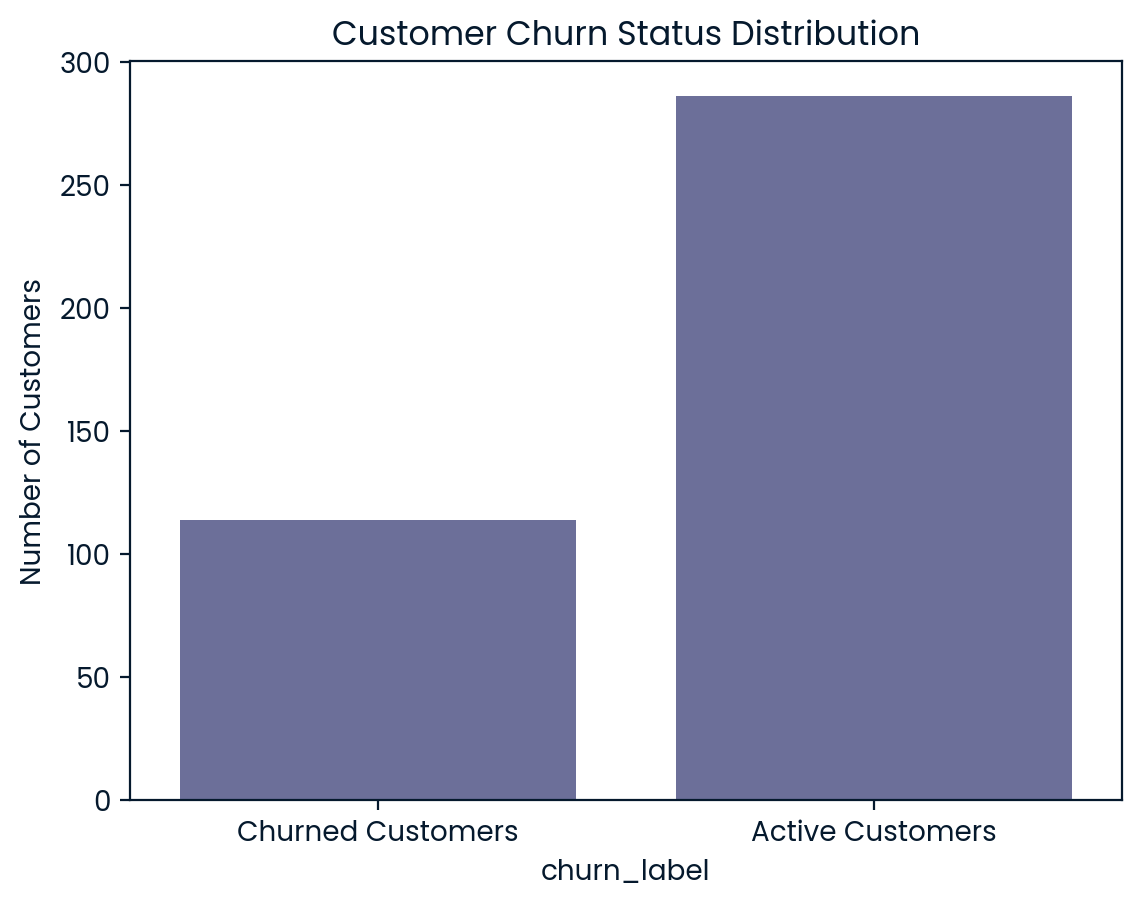

In [11]:
# Churn Distribution
current_churn_rate= account_info['churn_label'].value_counts(normalize=True)
print(f"Current Churn Rate:")
for churn, churn_rate in current_churn_rate.items():
    print(f"{churn.title()}: {churn_rate * 100:.1f}%")

sns.countplot(data=account_info, x='churn_label')
plt.title('Customer Churn Status Distribution')
plt.ylabel('Number of Customers')
plt.show()

## Support Ticket Resolution Time

The distribution of support ticket resolution times was reviewed to understand the customer support experience.

The average customer-level resolution time was 10.23 hours.

The analysis also compared average resolution time between active and churned customers to investigate whether support experience was associated with churn.

Average Resolution Time per Customer: 10.23 hours


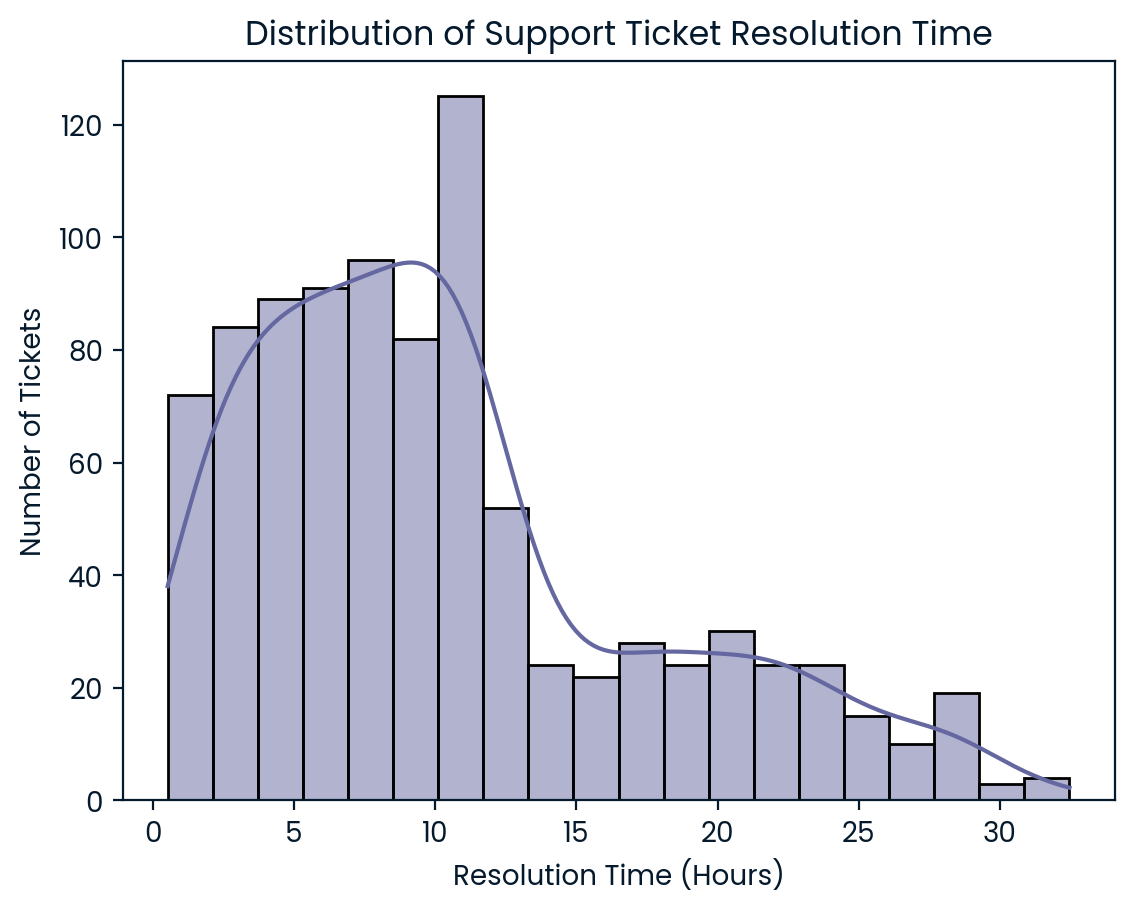

In [12]:
# resolution distribution
current_avg_resolution_time= round(support_summary['avg_resolution_time'].mean(),2)
print(f"Average Resolution Time per Customer: {current_avg_resolution_time} hours")

sns.histplot(data=customer_support,x='resolution_time_hours',kde=True)
plt.title('Distribution of Support Ticket Resolution Time')
plt.xlabel('Resolution Time (Hours)')
plt.ylabel('Number of Tickets')
plt.show()

## Churn Rate by Plan

The Free plan had the highest churn rate at 40.95%.

The churn rates for the other plans were:

- Enterprise: 26.09%
- Basic: 23.73%
- Pro: 22.35%

The substantially higher churn rate among Free-plan customers suggests that this customer segment should be a priority for further investigation and retention efforts.

Churn Rate by Plan: 
Basic: 23.73%
Enterprise: 26.09%
Free: 40.95%
Pro: 22.35%


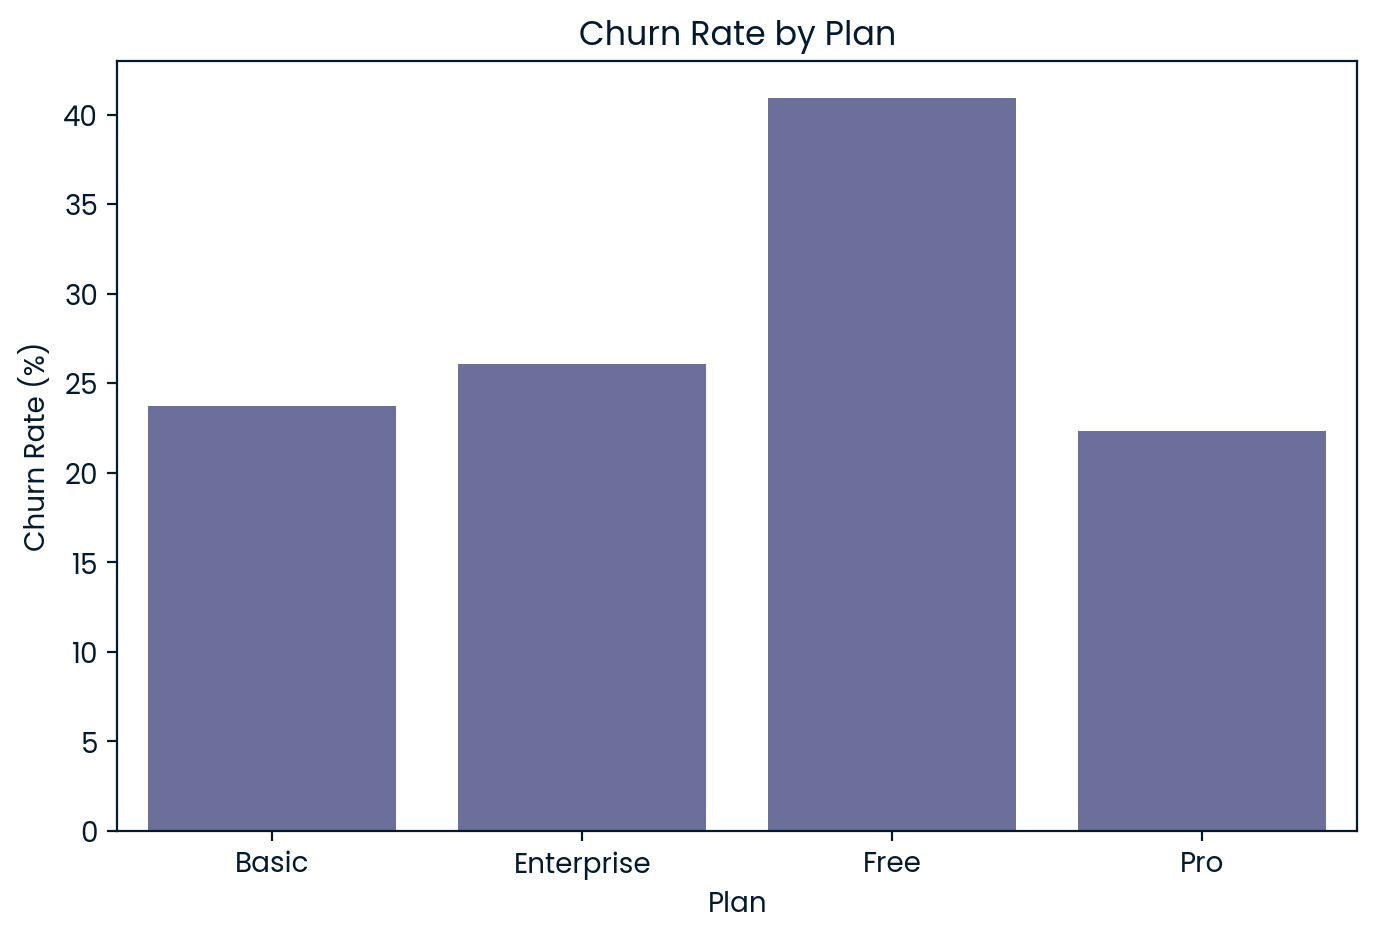

In [13]:
# churn rate by plan
churn_by_plan= account_info.groupby('plan')['churn_status'].apply(lambda x: (x=='Yes').mean()*100).reset_index(name='churn_rate').round(2)
print(f"Churn Rate by Plan: ")
for _,row in churn_by_plan.iterrows():
    print(f"{row['plan'].title()}: {row['churn_rate']}%")

plt.close('all')
plt.figure(figsize=(8, 5))

sns.barplot(data= churn_by_plan, x='plan',y='churn_rate')
plt.title('Churn Rate by Plan')
plt.xlabel('Plan')
plt.ylabel('Churn Rate (%)')
plt.show()

## Support Resolution Time and Churn

Churned customers had a much higher average customer-level resolution time than active customers.

- Active Customers: 6.66 hours
- Churned Customers: 18.69 hours

The average resolution time for churned customers was approximately 2.8 times higher than for active customers.

This shows a strong association between longer support resolution times and customer churn. However, this analysis does not prove that longer resolution times directly cause churn.


Average Resolution Time by Customer Churn Status: 
Active Customers: 6.66 hours
Churned Customers: 18.69 hours


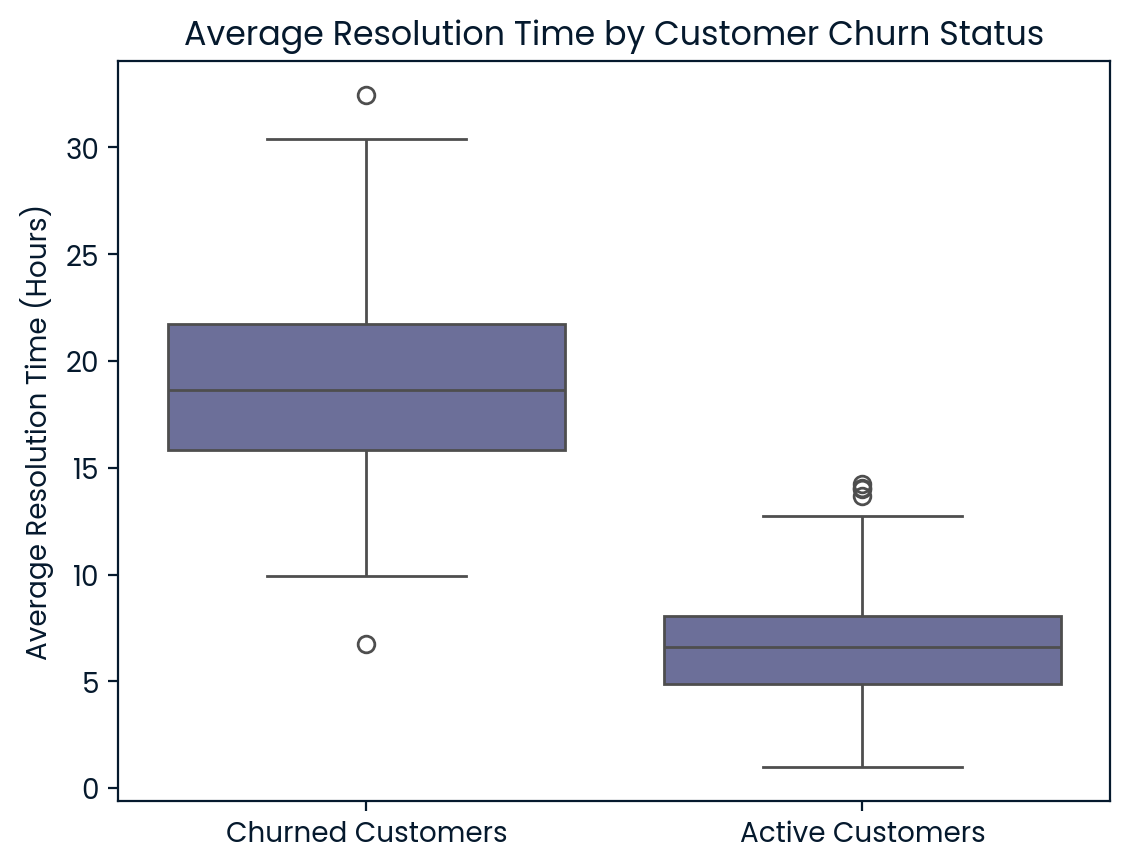

In [14]:
# Average Resolution Time by Customer Churn Status
avg_resolution_by_churn= churn_analysis.groupby('churn_label')['avg_resolution_time'].mean().round(2)
print(f"Average Resolution Time by Customer Churn Status: ")
for churn, avg_time in avg_resolution_by_churn.items():
    print(f"{churn.title()}: {avg_time} hours")

sns.boxplot(data= churn_analysis, x='churn_label',y='avg_resolution_time')
plt.title('Average Resolution Time by Customer Churn Status')
plt.xlabel('')
plt.ylabel('Average Resolution Time (Hours)')
plt.show()

## User Engagement and Churn

Among customers with recorded activity, churned customers had lower average activity than active customers.

- Active Customers: 1.88 recorded activities
- Churned Customers: 1.32 recorded activities

This suggests that lower customer engagement is associated with higher observed churn. Declining activity may therefore be useful as an early warning signal for customers who are at risk of leaving.

Average Activities Count by Churn Status: 
Active Customers: 1.88 activities
Churned Customers: 1.32 activities


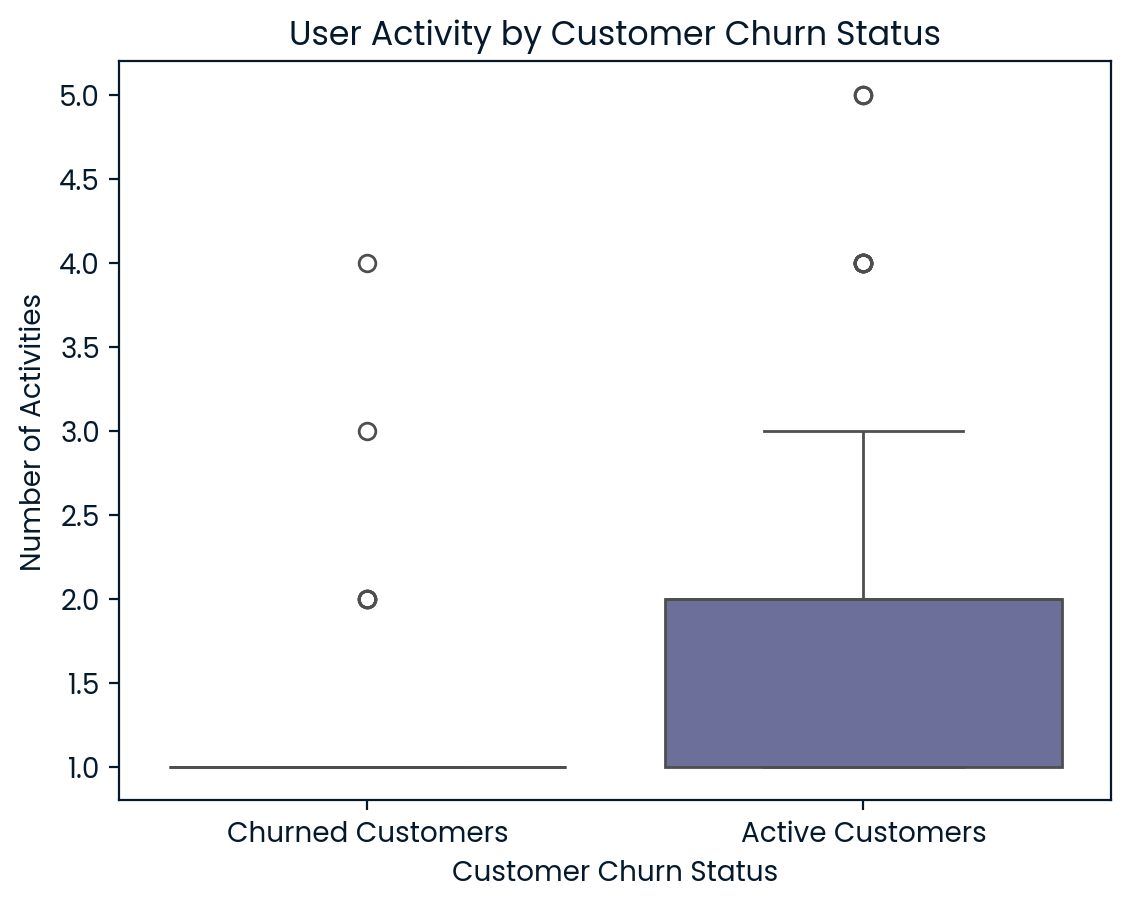

In [15]:
# activity count vs churn
avg_activity_by_churn= churn_analysis.groupby('churn_label')['activity_count'].mean().round(2)
print(f"Average Activities Count by Churn Status: ")
for churn, avg_activity in avg_activity_by_churn.items():
    print(f"{churn.title()}: {avg_activity} activities")

sns.boxplot(data= churn_analysis, x='churn_label' ,y='activity_count')
plt.title('User Activity by Customer Churn Status')
plt.xlabel('Customer Churn Status')
plt.ylabel('Number of Activities')
plt.show()

## Key Findings

The analysis identified three main findings:

1. The overall customer churn rate is 28.5%. This provides a baseline for monitoring customer retention.

2. The Free plan has the highest churn rate at 40.95%. This is substantially higher than the Pro plan, which has the lowest churn rate at 22.35%.

3. Churned customers show longer support resolution times and lower recorded activity. Churned customers had an average resolution time of 18.69 hours compared with 6.66 hours for active customers. Among customers with recorded activity, churned customers also had lower average activity levels.

These findings suggest that subscription plan, customer engagement, and customer support experience are all important areas to consider when investigating customer churn.

## Business Metric

1. Primary KPI: Overall Customer Churn Rate

 - The primary KPI Fit.ly Tech should monitor is the Overall Customer Churn Rate.
 - The current baseline is 28.5%.
 - Fit.ly Tech should track this metric regularly, such as monthly or quarterly, and compare it against previous periods to measure whether retention is improving.

2. The business should also monitor supporting metrics such as churn rate by plan, customer activity, and average support resolution time. These metrics can help explain changes in the overall churn rate.

## Recommendations
1. Improve Support Resolution
 
- Churned customers had a much longer average resolution time than active customers.
- Prioritise tickets from at-risk customers.
- Set faster response and resolution targets.
- Review long-running tickets regularly.

2. Improve Free-Plan Retention

- Free-plan users have the highest churn rate at 40.95%.
- Find out why Free users leave.
- Test targeted offers or upgrade messages.

3. Re-engage Low-Activity Customers

- Churned customers had lower activity than active customers.
- Identify customers with declining activity.
- Send personalised workout recommendations.
- Use reminders to bring customers back.

## Conclusion

The analysis shows that Fit.ly Tech currently has a customer churn rate of 28.5%.

Churn is highest among Free-plan customers, while churned customers also show longer support resolution times and lower recorded activity.

Based on these findings, Fit.ly Tech should focus on improving support resolution for at-risk customers, developing targeted retention strategies for Free-plan customers, and using declining engagement as an early warning signal.

The Overall Customer Churn Rate of 28.5% should be used as the primary KPI to monitor the success of future retention efforts.